In [55]:
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

In [32]:
sqy2h_outputs_dir = "../3_outputs/sqY2H"
metadata_outputs_dir = "../../../1_allele_collection/3_outputs"
integrative_inputs = "../../../3_integrated_assay_results/1_inputs"

In [33]:
# process metadata
metadata = pl.DataFrame(pd.read_csv(f"{metadata_outputs_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad.tsv", sep="\t"))
mut_cols = ["mutation_id_rc4", "mutation_id_cegs2", "mutation_id_edgotyping3"]
id_vars = [col for col in metadata.columns if col not in mut_cols]
# metadata = metadata.unpivot(index=id_vars, 
#                             on=mut_cols,
#                             variable_name="mutation_collection",
#                             value_name="mut_id")

priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]
metadata = metadata.select(priority_col).filter(~pl.col("mut_id").is_null()).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id"),
    pl.col("orf_id").cast(pl.Int64).alias("orf_id")
)

In [34]:
# merge scores with metadata
scores = pl.read_csv(f"{sqy2h_outputs_dir}/5_variant_perturbation_scores_automated_summed.csv").with_columns(
    pl.col("db_orf_id").cast(pl.Int64).alias("orf_id"),
    pl.col("db_mut_id").cast(pl.Int64).alias("mut_id"),
).drop(["db_orf_id", "db_mut_id"])

scores = scores.join(metadata, on=["orf_id", "mut_id"])
# scores.write_csv(f"{sqy2h_outputs_dir}/6_variant_perturbation_scores_annotated.csv")
# scores.write_csv(f"{integrative_inputs}/ppi_scores.csv")
# scores = scores.filter(pl.col("clinvar_clnsig_clean") != "5_Others")

In [35]:
scores = scores.with_columns(
    (pl.col("normalized_euclid_distance") / scores["normalized_euclid_distance"].max()).alias("normalized_euclid_distance_normalized")
)

In [36]:
scores_pd = scores.to_pandas()
scores_pd.clinvar_clnsig_clean.value_counts()

clinvar_clnsig_clean
1_Pathogenic     239
4_VUS             91
3_Conflicting     75
5_Others          42
2_Benign          30
Name: count, dtype: int64

In [37]:
scores_pd

,euclid_distance,num_edges,num_zero_wt,num_per_0.0,num_per_0.1,num_per_0.2,num_per_0.3,num_per_0.4,num_per_0.5,num_edge_0.0,...,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,normalized_euclid_distance_normalized
0,2161.082003,1,0,0,0,0,0,0,0,1,...,EZH2_Arg684Cys,143,213584,EZH2,Arg684Cys,ENSG00000106462,1_Pathogenic,NaN,2.0,0.227048
1,914.945156,1,0,0,0,0,0,0,0,1,...,PTS_Arg25Gln,145,200059,PTS,Arg25Gln,ENSG00000150787,1_Pathogenic,6.990040e-07,2.0,0.096126
2,333.585632,1,0,0,0,0,0,0,0,1,...,PTS_Asp116Gly,145,200065,PTS,Asp116Gly,ENSG00000150787,3_Conflicting,4.105980e-06,1.0,0.035047
3,1493.637960,1,0,1,1,1,1,1,1,1,...,MVK_His20Pro,281,3,MVK,His20Pro,ENSG00000110921,1_Pathogenic,9.603990e-06,2.0,0.156925
4,724.060184,1,0,0,0,0,0,0,0,1,...,MVK_Ser52Asn,281,5,MVK,Ser52Asn,ENSG00000110921,2_Benign,1.106140e-01,2.0,0.076071
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
477,5942.247226,2,0,1,1,1,1,1,1,2,...,KCNJ2_Arg312His,100016069,2649,KCNJ2,Arg312His,ENSG00000123700,1_Pathogenic,6.840540e-07,2.0,0.441451
478,6551.055740,2,0,1,1,1,1,1,1,2,...,KCNJ2_Glu349Lys,100016069,2654,KCNJ2,Glu349Lys,ENSG00000123700,3_Conflicting,1.299710e-05,1.0,0.486680
479,5928.078910,2,0,2,2,2,2,2,2,2,...,KCNJ2_Thr400Met,100016069,2656,KCNJ2,Thr400Met,ENSG00000123700,3_Conflicting,5.198930e-05,1.0,0.440399
480,6383.050548,2,0,2,2,2,2,2,2,2,...,KCNJ2_Pro415Leu,100016069,2659,KCNJ2,Pro415Leu,ENSG00000123700,3_Conflicting,1.238130e-04,1.0,0.474199


In [49]:
# Drop duplicates on allele_0, keeping the one with higher mut_id value
scores_dedup = scores.sort("mut_id", descending=True).unique(subset=["allele_0"], keep="first")

scores_dedup.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("allele_0").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance_normalized", "allele_0", "clinvar_clnsig_clean"])
).write_csv("../3_outputs/sqY2H/PPI_referenceSet.csv")

scores_dedup.with_columns(
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("allele_0").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/PPI_allScores.csv")

In [50]:
scores_dedup

euclid_distance,num_edges,num_zero_wt,num_per_0.0,num_per_0.1,num_per_0.2,num_per_0.3,num_per_0.4,num_per_0.5,num_edge_0.0,num_edge_0.1,num_edge_0.2,num_edge_0.3,num_edge_0.4,num_edge_0.5,frac_per_0.0,frac_per_0.1,frac_per_0.2,frac_per_0.3,frac_per_0.4,frac_per_0.5,normalized_euclid_distance,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,normalized_euclid_distance_normalized
f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64,f64
6964.535265,3,0,1,1,1,1,1,1,3,3,3,3,3,3,0.333333,0.333333,0.333333,0.333333,0.333333,0.333333,4020.97631,"""KRT6A""","""Ile462Asn""","""1385T>A""","""ENSG00000205420""","""CEGS2""","""1_Pathogenic""",null,2.0,"""KRT6A_Ile462Asn""",4870,215289,"""KRT6A""","""Ile462Asn""","""ENSG00000205420""","""1_Pathogenic""",null,2.0,0.422453
4674.011942,1,0,0,0,0,0,0,0,1,1,1,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,4674.011942,"""VHL""","""Leu122Pro""","""365T>C""","""ENSG00000134086""","""CEGS2""","""1_Pathogenic""",null,2.0,"""VHL_Leu122Pro""",13320,204010,"""VHL""","""Leu122Pro""","""ENSG00000134086""","""1_Pathogenic""",null,2.0,0.491063
3844.156989,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1.0,1.0,1.0,1.0,1.0,1.0,3844.156989,"""AGXT""","""Glu371Lys""","""1111G>A""","""ENSG00000172482""","""Edgotyping3""","""3_Conflicting""",0.000141,1.0,"""AGXT_Glu371Lys""",70497,3888,"""AGXT""","""Glu371Lys""","""ENSG00000172482""","""3_Conflicting""",0.000141,1.0,0.403876
1743.279762,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1.0,1.0,1.0,1.0,1.0,1.0,1743.279762,"""TTR""","""Thr69Ala""","""205A>G""","""ENSG00000118271""","""CEGS2""","""1_Pathogenic""",null,null,"""TTR_Thr69Ala""",8999,203000,"""TTR""","""Thr69Ala""","""ENSG00000118271""","""1_Pathogenic""",null,null,0.183153
1522.891571,1,0,0,0,0,0,0,0,1,1,1,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,1522.891571,"""GALE""","""Gly302Asp""","""905G>A""","""ENSG00000117308""","""CEGS2""","""1_Pathogenic""",null,2.0,"""GALE_Gly302Asp""",2767,214362,"""GALE""","""Gly302Asp""","""ENSG00000117308""","""1_Pathogenic""",0.00001,2.0,0.159999
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2242.004187,2,0,0,0,0,0,0,0,2,2,2,2,2,2,0.0,0.0,0.0,0.0,0.0,0.0,1585.336364,"""TPM1""","""Val95Ala""","""284T>C""","""ENSG00000140416""","""RC4""","""1_Pathogenic""",null,2.0,"""TPM1_Val95Ala""",4723,8950,"""TPM1""","""Val95Ala""","""ENSG00000140416""","""1_Pathogenic""",null,2.0,0.166559
963.70067,1,0,0,0,0,0,0,0,1,1,1,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,963.70067,"""PKP2""","""Met365Val""","""1093A>G""","""ENSG00000057294""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""PKP2_Met365Val""",54308,3088,"""PKP2""","""Met365Val""","""ENSG00000057294""","""3_Conflicting""",0.000222,1.0,0.101249
4542.051017,2,0,1,1,1,1,1,1,2,2,2,2,2,2,0.5,0.5,0.5,0.5,0.5,0.5,3211.715075,"""TMEM43""","""Arg312Trp""","""934C>T""","""ENSG00000170876""","""CEGS2""","""2_Benign""",0.0127671,2.0,"""TMEM43_Arg312Trp""",3438,201181,"""TMEM43""","""Arg312Trp""","""ENSG00000170876""","""2_Benign""",0.0127671,2.0,0.33743


In [52]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_bcv.log" --bandwidth "bcv" --printTransitions 
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_default.log" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_sj.log" --printTransitions --bandwidth "SJ"
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-07-25_17:45:34 INFO: Reading input 
2025-07-25_17:45:34 INFO: Calculating densties 


Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-07-25_17:45:35 INFO: Drawing LLR plot 
2025-07-25_17:45:35 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-25_17:45:35 INFO: Category transitions:  
0.503 : none -> patho.support
0.593 : patho.support -> patho.moderate
0.632 : patho.moderate -> patho.strong
0.645 : patho.strong -> patho.vstrong
2025-07-25_17:45:35 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-07-25_17:45:35 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv.csv 
2025-07-25_17:45:35 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

2025-07-25_17:45:39 INFO: Reading input 
2025-07-25_17:45:39 INFO: Calculating densties 
2025-07-25_17:45:40 INFO: Drawing LLR plot 
2025-07-25_17:45:40 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-25_17:45:41 INFO: Category transitions:  
0.526 : none -> patho.support
0.565 : patho.support -> patho.moderate
0.596 : patho.moderate -> patho.strong
0.607 : patho.strong -> patho.vstrong
2025-07-25_17:45:41 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-07-25_17:45:41 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd.csv 
2025-07-25_17:45:41 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-07-25_17:45:41 INFO: Reading input 
2025-07-25_17:45:41 INFO: Calculating densties 
2025-07-25_17:45:42 INFO: Drawing LLR plot 
2025-07-25_17:45:42 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-25_17:45:43 INFO: Category transitions:  
0.513 : none -> patho.support
0.547 : patho.support -> patho.moderate
0.579 : patho.moderate -> patho.strong
0.588 : patho.strong -> patho.vstrong
2025-07-25_17:45:43 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-07-25_17:45:43 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj.csv 
2025-07-25_17:45:43 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-07-25_17:45:43 INFO: Reading input 
2025-07-25_17:45:43 INFO: Calculating densties 
2025-07-25_17:45:44 INFO: Drawing LLR plot 
2025-07-25_17:45:44 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-25_17:45:45 INFO: Category transitions:  
0.526 : none -> patho.support
0.565 : patho.support -> patho.moderate
0.596 : patho.moderate -> patho.strong
0.607 : patho.strong -> patho.vstrong
2025-07-25_17:45:45 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-07-25_17:45:45 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd.csv 
2025-07-25_17:45:45 INFO: Done! 


In [ ]:
# %%bash
# # source ~/software/anaconda3/etc/profile.d/conda.sh
# conda activate py310

# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_bcv.log" --bandwidth "bcv" --printTransitions --outlierSuppression 0.2
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --outlierSuppression 0.1


# ## Non-smooth, failed bandwidth:
# ## No need to run any more
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_default.log" --printTransitions
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_sj.log" --printTransitions --bandwidth "SJ"
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions

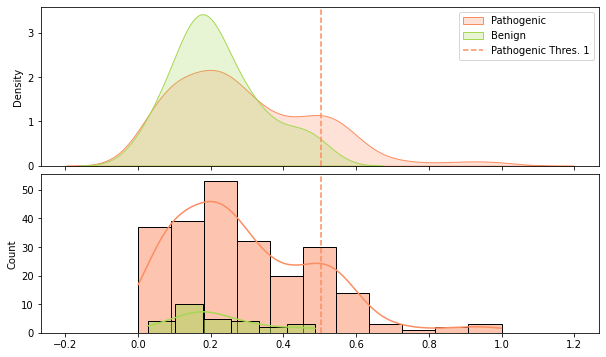

In [57]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
plt.show()

In [ ]:
num_edge_filter = 1

benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
print(benign_scores.shape)

path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
print(path_scores.shape)

vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
print(vus_scores.shape)

conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
print(conf_scores.shape)

print(f"With this threshold, we capture {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} benign alleles at ~5% error rate, which is {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}% of the benign alleles.")
print(f"With this threshold, we capture {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} pathogenic alleles at ~5% error rate, which is {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}% of the pathogenic alleles.")
print(f"With this threshold, we classify {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} VUS and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} conflicting alleles as pathogenic at ~5% error rate, which is {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}% and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}% of the VUS and conflicting alleles, respectively.")


(30, 40)
(239, 40)
(91, 40)
(75, 40)
With this path_thres, we capture 0 benign alleles at ~5% error rate, which is 0.00% of the benign alleles.
With this path_thres, we capture 44 pathogenic alleles at ~5% error rate, which is 18.41% of the pathogenic alleles.
With this path_thres, we classify 9 VUS and 5 conflicting alleles as pathogenic at ~5% error rate, which is 9.89% and 6.67% of the VUS and conflicting alleles, respectively.
